# 03 - Model Training v2: Random Forest (lần chạy 2)

Thực nghiệm theo `reports/Phan_tich_overfit_va_huong_cai_tien.txt`:

| Bước | Nội dung | Dùng tập test? |
|---|---|---|
| 1 | Tách validation (80/20, stratified) + OOB, chạy lại baseline lần 1 | Không |
| 2 | RandomizedSearchCV (5-fold CV trên train) | Không |
| 3 | Chọn ngưỡng quyết định bằng `TunedThresholdClassifierCV` | Không |
| 4 | Model cuối cùng: đánh giá **một lần** trên tập test, so sánh với lần 1 | Có (1 lần) |
| 5 | Thực nghiệm phụ về lệch phân bố (adversarial validation, importance weighting, feature tỷ lệ) | Có dùng **feature** của test (không dùng nhãn), **chỉ để tham khảo** |

Kết quả chính của lần 2 là bước 4. Bước 5 không dùng để chọn model chính.

In [1]:
import os

# Tự nhận diện môi trường: Colab (mount Google Drive) hoặc máy local (Google Drive for Desktop)
try:
    from google.colab import drive
    drive.mount('/content/drive')
    BASE = '/content/drive/MyDrive/5G_IDS_Project'
except ImportError:
    # Notebook nằm trong 5G_IDS_Project/notebooks -> thư mục project là thư mục cha
    BASE = os.path.abspath('..')

print("Thư mục project:", BASE)

Thư mục project: G:\.shortcut-targets-by-id\1C2Fd9KvthwrCJvr4mxV0l6w7K1lsUbNE\5G_IDS_Project


In [2]:
import json
import numpy as np
import pandas as pd

QUICK = os.environ.get('QUICK') == '1'   # chạy thử nhanh để kiểm tra code
RS = 42
N_TREES = 30 if QUICK else 300          # số cây cho model cuối
N_TREES_SEARCH = 20 if QUICK else 200   # số cây khi tìm tham số
N_ITER = 3 if QUICK else 30             # số tổ hợp tham số thử
CV = 2 if QUICK else 5

cleaned_dir = os.path.join(BASE, 'data', 'cleaned')
models_dir = os.path.join(BASE, 'models')
train = pd.read_parquet(os.path.join(cleaned_dir, 'UNSW_NB15_training-set.parquet'))
test = pd.read_parquet(os.path.join(cleaned_dir, 'UNSW_NB15_testing-set.parquet'))

target_cols = ['label', 'attack_cat']
categorical_cols = ['proto', 'service', 'state']
X = train.drop(columns=target_cols).astype({c: str for c in categorical_cols}); y = train['label']
X_test = test.drop(columns=target_cols).astype({c: str for c in categorical_cols}); y_test = test['label']

removed_cols = ['id', 'ct_state_ttl', 'sttl', 'dttl', 'ct_dst_ltm', 'ct_srv_dst', 'ct_dst_src_ltm', 'ct_srv_ltm',
                'ct_srv_src', 'ct_dst_sport_ltm', 'is_sm_ips_ports', 'ct_ftp_cmd', 'is_ftp_login']
assert not set(target_cols + removed_cols) & set(X.columns) and list(X.columns) == list(X_test.columns)
print('QUICK mode' if QUICK else 'FULL mode', '| train', X.shape, '| test', X_test.shape)

FULL mode | train (98934, 31) | test (50567, 31)


In [3]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score, balanced_accuracy_score,
                             roc_auc_score, average_precision_score, confusion_matrix)


def make_model(**rf_params):
    # Cùng pipeline với notebook 02: one-hot (fit trên train) + Random Forest
    preprocess = ColumnTransformer([('cat', OneHotEncoder(handle_unknown='ignore'), categorical_cols)],
                                   remainder='passthrough', verbose_feature_names_out=False)
    params = dict(n_estimators=100, random_state=RS, n_jobs=-1) | rf_params
    return Pipeline([('preprocess', preprocess), ('rf', RandomForestClassifier(**params))])


def evaluate(model, X_, y_, threshold=None):
    # threshold=None: dùng model.predict (như lần 1); ngược lại: Attack nếu P(Attack) >= threshold
    proba = model.predict_proba(X_)[:, 1]
    pred = model.predict(X_) if threshold is None else (proba >= threshold).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_, pred, labels=[0, 1]).ravel()
    return {'accuracy': accuracy_score(y_, pred), 'precision': precision_score(y_, pred, zero_division=0),
            'recall': recall_score(y_, pred), 'f1': f1_score(y_, pred), 'fpr': fp / (fp + tn),
            'balanced_acc': balanced_accuracy_score(y_, pred), 'roc_auc': roc_auc_score(y_, proba),
            'pr_auc': average_precision_score(y_, proba), 'tn': int(tn), 'fp': int(fp), 'fn': int(fn), 'tp': int(tp)}


def show(results):
    df = pd.DataFrame(results).T
    display(df.style.format({c: '{:.4f}' for c in df.columns if c not in ('tn', 'fp', 'fn', 'tp')}))

In [4]:
# Kiểm tra dòng trùng GIỮA train và test (đề xuất 4d)
key_cols = list(X.columns) + ['label']
overlap = test[key_cols].astype(str).merge(train[key_cols].astype(str).drop_duplicates(), how='inner')
print(f'Dòng test trùng hoàn toàn (feature + label) với một dòng train: {len(overlap)} / {len(test)} '
      f'({len(overlap) / len(test):.2%})')
print(overlap['label'].value_counts().rename('theo label').to_dict())

Dòng test trùng hoàn toàn (feature + label) với một dòng train: 1993 / 50567 (3.94%)
{'1': 1653, '0': 340}


## Bước 1 - Validation + OOB, chạy lại baseline lần 1

In [5]:
from sklearn.model_selection import train_test_split
import joblib

X_tr, X_val, y_tr, y_val = train_test_split(X, y, test_size=0.2, stratify=y, random_state=RS)
print(f'Train-fit: {len(X_tr)} | Validation: {len(X_val)}')

baseline = make_model(oob_score=True).fit(X_tr, y_tr)   # cấu hình lần 1 (mặc định)
results_step1 = {
    'Baseline - train-fit': evaluate(baseline, X_tr, y_tr),
    'Baseline - validation': evaluate(baseline, X_val, y_val),
}
show(results_step1)
print(f"OOB accuracy: {baseline.named_steps['rf'].oob_score_:.4f}")

# Kết quả lần 1 trên tập test (model đã lưu ở notebook 02, train trên toàn bộ tập train)
run1 = joblib.load(os.path.join(models_dir, 'random_forest.joblib'))
run1_test = evaluate(run1, X_test, y_test)

Train-fit: 79147 | Validation: 19787


,accuracy,precision,recall,f1,fpr,balanced_acc,roc_auc,pr_auc,tn,fp,fn,tp
Baseline - train-fit,1.0000,1.0000,1.0000,1.0000,0.0000,1.0000,1.0000,1.0000,39860.000000,0.000000,0.000000,39287.000000
Baseline - validation,0.9268,0.9055,0.9519,0.9281,0.0979,0.9270,0.9841,0.9815,8989.000000,976.000000,472.000000,9350.000000


OOB accuracy: 0.9229


## Bước 2 - Tìm tham số (RandomizedSearchCV, chỉ trên phần train-fit)

Không gian tìm kiếm theo Probst et al. (2019): `max_features`, `min_samples_leaf`, `max_samples`, `class_weight`, `max_depth`. Chỉ số chọn: `average_precision` (PR-AUC), không phụ thuộc ngưỡng, vì ngưỡng được chọn riêng ở bước 3.

In [6]:
from sklearn.model_selection import RandomizedSearchCV, StratifiedKFold

param_distributions = {
    'rf__max_features': ['sqrt', 0.1, 0.2, 0.3, 0.5],
    'rf__min_samples_leaf': [1, 2, 3, 5, 10],
    'rf__max_samples': [None, 0.5, 0.7],
    'rf__class_weight': [None, 'balanced', 'balanced_subsample'],
    'rf__max_depth': [None, 20, 30],
}
cv = StratifiedKFold(n_splits=CV, shuffle=True, random_state=RS)
search = RandomizedSearchCV(make_model(n_estimators=N_TREES_SEARCH), param_distributions, n_iter=N_ITER,
                            scoring='average_precision', cv=cv, random_state=RS, refit=False,
                            return_train_score=True, n_jobs=1)
search.fit(X_tr, y_tr)

cv_results = pd.DataFrame(search.cv_results_)
cols = ['rank_test_score', 'mean_test_score', 'std_test_score', 'mean_train_score'] + [f'param_{p}' for p in param_distributions]
display(cv_results[cols].sort_values('rank_test_score').head(10))
best_params = {k.replace('rf__', ''): v for k, v in search.best_params_.items()}
print('Tham số tốt nhất:', best_params, f'| CV PR-AUC = {search.best_score_:.4f}')

,rank_test_score,mean_test_score,std_test_score,mean_train_score,param_rf__max_features,param_rf__min_samples_leaf,param_rf__max_samples,param_rf__class_weight,param_rf__max_depth
23,1,0.982862,0.001522,0.998879,0.5,1,0.7,NaN,20
2,2,0.982812,0.001430,0.996981,0.5,5,0.7,balanced_subsample,30
8,3,0.982663,0.001394,0.999561,0.5,3,None,balanced_subsample,30
28,4,0.982605,0.001414,0.994285,0.3,10,None,balanced,None
7,5,0.982585,0.001351,0.999216,0.2,3,None,balanced,None
29,6,0.982575,0.001632,0.998827,0.5,3,0.7,balanced,30
27,7,0.982486,0.001445,0.995352,0.5,5,0.5,balanced_subsample,None
20,8,0.982467,0.001707,0.998212,0.2,3,0.7,NaN,30
15,9,0.982321,0.001521,0.997269,0.3,3,0.5,balanced,None
25,10,0.982219,0.001590,0.994342,0.2,5,0.7,NaN,20


Tham số tốt nhất: {'min_samples_leaf': 1, 'max_samples': 0.7, 'max_features': 0.5, 'max_depth': 20, 'class_weight': None} | CV PR-AUC = 0.9829


In [7]:
tuned = make_model(n_estimators=N_TREES, oob_score=True, **best_params).fit(X_tr, y_tr)
results_step2 = {
    'Tuned - train-fit': evaluate(tuned, X_tr, y_tr),
    'Tuned - validation': evaluate(tuned, X_val, y_val),
}
show({**results_step1, **results_step2})
print(f"OOB accuracy (tuned): {tuned.named_steps['rf'].oob_score_:.4f}")

,accuracy,precision,recall,f1,fpr,balanced_acc,roc_auc,pr_auc,tn,fp,fn,tp
Baseline - train-fit,1.0000,1.0000,1.0000,1.0000,0.0000,1.0000,1.0000,1.0000,39860.000000,0.000000,0.000000,39287.000000
Baseline - validation,0.9268,0.9055,0.9519,0.9281,0.0979,0.9270,0.9841,0.9815,8989.000000,976.000000,472.000000,9350.000000
Tuned - train-fit,0.9775,0.9662,0.9893,0.9776,0.0341,0.9776,0.9985,0.9985,38500.000000,1360.000000,422.000000,38865.000000
Tuned - validation,0.9322,0.9104,0.9577,0.9335,0.0929,0.9324,0.9860,0.9849,9039.000000,926.000000,415.000000,9407.000000


OOB accuracy (tuned): 0.9280


## Bước 3 - Chọn ngưỡng quyết định (TunedThresholdClassifierCV)

Ngưỡng tối ưu F1 được chọn bằng cross-validation **bên trong** phần train-fit, sau đó kiểm tra trên validation.

In [8]:
from sklearn.model_selection import TunedThresholdClassifierCV

tt_val = TunedThresholdClassifierCV(make_model(n_estimators=N_TREES, **best_params), scoring='f1',
                                    cv=StratifiedKFold(n_splits=CV, shuffle=True, random_state=RS))
tt_val.fit(X_tr, y_tr)
print(f'Ngưỡng chọn bằng CV trên train-fit: {tt_val.best_threshold_:.3f} (F1 CV = {tt_val.best_score_:.4f})')

results_step3 = {
    'Tuned, ngưỡng 0.5 - validation': evaluate(tuned, X_val, y_val),
    'Tuned + ngưỡng CV - validation': evaluate(tt_val.estimator_, X_val, y_val, threshold=tt_val.best_threshold_),
}
show(results_step3)

Ngưỡng chọn bằng CV trên train-fit: 0.505 (F1 CV = 0.9280)


,accuracy,precision,recall,f1,fpr,balanced_acc,roc_auc,pr_auc,tn,fp,fn,tp
"Tuned, ngưỡng 0.5 - validation",0.9322,0.9104,0.9577,0.9335,0.0929,0.9324,0.9860,0.9849,9039.000000,926.000000,415.000000,9407.000000
Tuned + ngưỡng CV - validation,0.9324,0.9123,0.9557,0.9335,0.0905,0.9326,0.9860,0.9849,9063.000000,902.000000,435.000000,9387.000000


## Bước 4 - Model cuối cùng của lần 2 và đánh giá trên tập test (một lần)

Fit lại trên **toàn bộ** tập train (giống lần 1) với tham số bước 2, ngưỡng chọn bằng CV trên toàn bộ tập train (bước 3).

In [9]:
final = TunedThresholdClassifierCV(make_model(n_estimators=N_TREES, **best_params), scoring='f1',
                                   cv=StratifiedKFold(n_splits=CV, shuffle=True, random_state=RS))
final.fit(X, y)
final_threshold = float(final.best_threshold_)
print(f'Ngưỡng cuối cùng: {final_threshold:.3f}')

run2_test = evaluate(final.estimator_, X_test, y_test, threshold=final_threshold)
comparison = {'Lần 1 (baseline, ngưỡng 0.5)': run1_test, 'Lần 2 (tuned + ngưỡng CV)': run2_test}
show(comparison)

if not QUICK:
    joblib.dump(final, os.path.join(models_dir, 'random_forest_v2.joblib'), compress=3)

Ngưỡng cuối cùng: 0.515


,accuracy,precision,recall,f1,fpr,balanced_acc,roc_auc,pr_auc,tn,fp,fn,tp
"Lần 1 (baseline, ngưỡng 0.5)",0.8176,0.6807,0.9459,0.7917,0.2567,0.8446,0.9554,0.9287,23812.000000,8222.000000,1003.000000,17530.000000
Lần 2 (tuned + ngưỡng CV),0.8276,0.6951,0.9436,0.8005,0.2395,0.8520,0.9603,0.9428,24363.000000,7671.000000,1046.000000,17487.000000


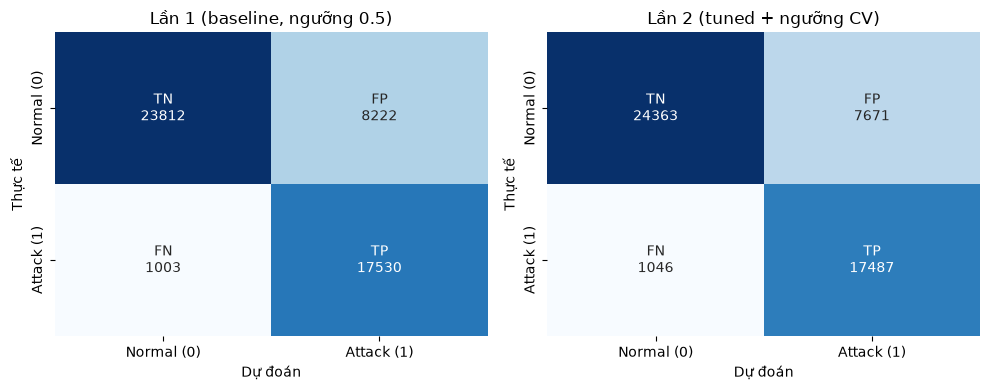

In [10]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, (name, r) in zip(axes, comparison.items()):
    cm = np.array([[r['tn'], r['fp']], [r['fn'], r['tp']]])
    annot = [[f"TN\n{r['tn']}", f"FP\n{r['fp']}"], [f"FN\n{r['fn']}", f"TP\n{r['tp']}"]]
    sns.heatmap(cm, annot=annot, fmt='', cmap='Blues', cbar=False, ax=ax,
                xticklabels=['Normal (0)', 'Attack (1)'], yticklabels=['Normal (0)', 'Attack (1)'])
    ax.set_xlabel('Dự đoán'); ax.set_ylabel('Thực tế'); ax.set_title(name)
plt.tight_layout()
plt.show()

In [11]:
# Recall theo từng loại tấn công trên tập test
attacks = test['label'] == 1
pred_run1 = run1.predict(X_test)
pred_run2 = (final.estimator_.predict_proba(X_test)[:, 1] >= final_threshold).astype(int)
per_cat = pd.DataFrame({
    'n': test.loc[attacks, 'attack_cat'].value_counts(),
    'recall_lan1': pd.Series(pred_run1[attacks], index=test.index[attacks]).groupby(test.loc[attacks, 'attack_cat'], observed=True).mean(),
    'recall_lan2': pd.Series(pred_run2[attacks], index=test.index[attacks]).groupby(test.loc[attacks, 'attack_cat'], observed=True).mean(),
}).query('n > 0').sort_values('n', ascending=False)
display(per_cat.round(4))

,n,recall_lan1,recall_lan2
attack_cat,,,
Exploits,7559,0.9836,0.9821
Fuzzers,4436,0.8158,0.8102
Reconnaissance,2262,0.9929,0.9929
DoS,1677,0.9893,0.9863
Generic,1430,0.9930,0.9937
Analysis,427,1.0000,1.0000
Shellcode,370,0.9514,0.9459
Backdoor,328,1.0000,0.9970
Worms,44,1.0000,1.0000


In [12]:
# Permutation importance (trên validation, model bước 2) so với MDI
from sklearn.inspection import permutation_importance

perm = permutation_importance(tuned, X_val, y_val, scoring='average_precision',
                              n_repeats=2 if QUICK else 5, random_state=RS, n_jobs=1)
perm_importance = pd.DataFrame({'perm_mean': perm.importances_mean, 'perm_std': perm.importances_std},
                               index=X_val.columns).sort_values('perm_mean', ascending=False)

rf = tuned.named_steps['rf']
names = tuned.named_steps['preprocess'].get_feature_names_out()
mdi = pd.Series(rf.feature_importances_, index=names)
mdi = mdi.groupby(lambda n: next((c for c in categorical_cols if n.startswith(c + '_')), n)).sum()
perm_importance['mdi'] = mdi
perm_importance['rank_perm'] = range(1, len(perm_importance) + 1)
perm_importance['rank_mdi'] = perm_importance['mdi'].rank(ascending=False).astype(int)
display(perm_importance.head(10).round(4))
if not QUICK:
    perm_importance.to_csv(os.path.join(models_dir, 'random_forest_v2_importance.csv'))

,perm_mean,perm_std,mdi,rank_perm,rank_mdi
ackdat,0.0501,0.0007,0.1694,1,2
sbytes,0.0257,0.0004,0.0366,2,8
dload,0.0202,0.0004,0.2446,3,1
dbytes,0.0125,0.0006,0.0787,4,4
smean,0.0114,0.0003,0.0324,5,9
service,0.0110,0.0007,0.0141,6,15
synack,0.0083,0.0003,0.0530,7,5
tcprtt,0.0072,0.0004,0.0813,8,3
dmean,0.0063,0.0001,0.0400,9,7
dloss,0.0056,0.0004,0.0147,10,14


## Bước 5 - Thực nghiệm phụ: xử lý lệch phân bố (CHỈ THAM KHẢO)

⚠️ Các thực nghiệm này dùng **feature (không dùng nhãn)** của tập test để đo độ lệch (bán-transductive), và kết quả được xem trực tiếp trên tập test. Chúng **không** dùng để chọn model chính ở bước 4, chỉ để đánh giá xem hướng xử lý lệch phân bố có đáng theo đuổi không.

- **5a** Validation "giống test": 20% dòng train giống tập test nhất (theo model adversarial) làm validation để chọn ngưỡng.
- **5b** Importance weighting: trọng số mẫu w = P(test|x) / P(train|x).
- **5c** Thêm feature tỷ lệ (byte/gói, tỷ lệ chiều đi/về) với quy trình sạch như bước 4.

In [13]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import precision_recall_curve

# Model adversarial: phân biệt dòng train (0) và dòng test (1) chỉ từ feature
A = pd.concat([X, X_test], ignore_index=True)
b = np.r_[np.zeros(len(X)), np.ones(len(X_test))]
adv_proba = cross_val_predict(make_model(), A, b, cv=StratifiedKFold(n_splits=CV, shuffle=True, random_state=RS),
                              method='predict_proba')[:, 1]
print(f'Adversarial AUC (train vs test): {roc_auc_score(b, adv_proba):.4f}')
p_test_like = pd.Series(adv_proba[:len(X)], index=X.index)

# 5a: 20% dòng train giống test nhất làm validation
val_adv = p_test_like >= p_test_like.quantile(0.8)
X_fit, y_fit = X[~val_adv], y[~val_adv]
X_vadv, y_vadv = X[val_adv], y[val_adv]
print(f'Validation giống test: {val_adv.sum()} dòng, tỷ lệ Normal = {(y_vadv == 0).mean():.3f}')


def f1_threshold(model, X_, y_):
    precision, recall, thr = precision_recall_curve(y_, model.predict_proba(X_)[:, 1])
    f1 = 2 * precision * recall / np.clip(precision + recall, 1e-12, None)
    return float(thr[np.argmax(f1[:-1])])


m5a = make_model(n_estimators=N_TREES, **best_params).fit(X_fit, y_fit)
thr5a = f1_threshold(m5a, X_vadv, y_vadv)

# 5b: importance weighting
w = (p_test_like / (1 - p_test_like)).clip(0.05, 20)[~val_adv]
w = w / w.mean()
m5b = make_model(n_estimators=N_TREES, **best_params).fit(X_fit, y_fit, rf__sample_weight=w.values)
thr5b = f1_threshold(m5b, X_vadv, y_vadv)
print(f'Ngưỡng 5a = {thr5a:.3f} | ngưỡng 5b = {thr5b:.3f}')

Adversarial AUC (train vs test): 0.8040
Validation giống test: 20249 dòng, tỷ lệ Normal = 0.440


Ngưỡng 5a = 0.461 | ngưỡng 5b = 0.428


In [14]:
# 5c: feature tỷ lệ (quy trình sạch như bước 4: ngưỡng chọn bằng CV trên train)
def add_ratio_features(df):
    df = df.copy()
    df['sbytes_per_pkt'] = df['sbytes'] / df['spkts'].clip(lower=1)
    df['dbytes_per_pkt'] = df['dbytes'] / df['dpkts'].clip(lower=1)
    df['bytes_ratio'] = df['dbytes'] / df['sbytes'].clip(lower=1)
    df['pkts_ratio'] = df['dpkts'] / df['spkts'].clip(lower=1)
    return df


X_r, X_test_r = add_ratio_features(X), add_ratio_features(X_test)
m5c = TunedThresholdClassifierCV(make_model(n_estimators=N_TREES, **best_params), scoring='f1',
                                 cv=StratifiedKFold(n_splits=CV, shuffle=True, random_state=RS)).fit(X_r, y)

results_step5 = {
    'Lần 1 (baseline)': run1_test,
    'Lần 2 - chính (bước 4)': run2_test,
    '5a: ngưỡng chọn trên validation giống test': evaluate(m5a, X_test, y_test, threshold=thr5a),
    '5b: 5a + importance weighting': evaluate(m5b, X_test, y_test, threshold=thr5b),
    '5c: bước 4 + feature tỷ lệ': evaluate(m5c.estimator_, X_test_r, y_test, threshold=m5c.best_threshold_),
}
show(results_step5)

,accuracy,precision,recall,f1,fpr,balanced_acc,roc_auc,pr_auc,tn,fp,fn,tp
Lần 1 (baseline),0.8176,0.6807,0.9459,0.7917,0.2567,0.8446,0.9554,0.9287,23812.000000,8222.000000,1003.000000,17530.000000
Lần 2 - chính (bước 4),0.8276,0.6951,0.9436,0.8005,0.2395,0.8520,0.9603,0.9428,24363.000000,7671.000000,1046.000000,17487.000000
5a: ngưỡng chọn trên validation giống test,0.7928,0.6454,0.9648,0.7734,0.3067,0.8290,0.9560,0.9376,22210.000000,9824.000000,653.000000,17880.000000
5b: 5a + importance weighting,0.7916,0.6441,0.9644,0.7723,0.3084,0.8280,0.9561,0.9369,22156.000000,9878.000000,659.000000,17874.000000
5c: bước 4 + feature tỷ lệ,0.8221,0.6852,0.9519,0.7968,0.2530,0.8494,0.9613,0.9441,23928.000000,8106.000000,892.000000,17641.000000


In [15]:
def clean(d):
    return {k: (round(float(v), 6) if isinstance(v, (float, np.floating)) else v) for k, v in d.items()}


summary = {
    'quick_mode': QUICK,
    'best_params': {k: (None if v is None else v) for k, v in best_params.items()},
    'cv_pr_auc': round(float(search.best_score_), 6),
    'threshold_final': round(final_threshold, 6),
    'oob_baseline': round(float(baseline.named_steps['rf'].oob_score_), 6),
    'oob_tuned': round(float(tuned.named_steps['rf'].oob_score_), 6),
    'train_test_overlap_rows': int(len(overlap)),
    'validation': {k: clean(v) for k, v in {**results_step1, **results_step2, **results_step3}.items()},
    'test': {k: clean(v) for k, v in results_step5.items()},
    'per_attack_cat_recall': per_cat.round(6).reset_index().to_dict(orient='records'),
    'thresholds_step5': {'5a': thr5a, '5b': thr5b, '5c': float(m5c.best_threshold_)},
}
out = os.path.join(models_dir if not QUICK else os.environ['TEMP'], 'random_forest_v2_metrics.json')
with open(out, 'w', encoding='utf-8') as f:
    json.dump(summary, f, ensure_ascii=False, indent=2, default=str)
print('Đã lưu:', out)

Đã lưu: G:\.shortcut-targets-by-id\1C2Fd9KvthwrCJvr4mxV0l6w7K1lsUbNE\5G_IDS_Project\models\random_forest_v2_metrics.json
